# 05 — Stronger backbones and a cross-backbone ensemble (round 3)

The optimised recipe from notebook 04 (448 px, 30 epochs, plain CE, 20-view TTA, logit adjustment) with the backbone swapped:

| Backbone | timm model | Pretraining | Params |
|---|---|---|---|
| ResNet-50 (reference) | `resnet50.tv2_in1k` | ImageNet-1k | 23.5M |
| ConvNeXt-S | `convnext_small.fb_in22k_ft_in1k` | ImageNet-22k | 49.5M |
| EfficientNetV2-S | `tf_efficientnetv2_s.in21k_ft_in1k` | ImageNet-21k | 20.2M |
| ViT-B/16 | `vit_base_patch16_224.augreg2_in21k_ft_in1k` | ImageNet-21k | 86.3M |
| DINOv2 ViT-B/14 | `vit_base_patch14_dinov2.lvd142m` | self-supervised, 142M images | 86.3M |

**Learning rate.** ResNet's 2e-4 is too high for transformers, so a fold-0 pilot at 224 px compared 2e-4 and 5e-5 per
backbone and kept the better one on CV. **Ensemble.** `ensemble_runs.py` averages the backbones' probabilities fold by fold,
so the ensemble is judged on CV like any single model.

**Reproduce:** pilot `slurm/run_jobs_node.sh slurm/jobs/round3_pilot.txt` (~20 min), then
`slurm/run_jobs_node.sh slurm/jobs/round3_backbones.txt slurm/jobs/round3_tta.txt` (~2.3 h), then adjustment + `ensemble_runs.py`.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HWX_DIR = Path.cwd() if (Path.cwd() / "isic").is_dir() else Path.cwd().parent
sys.path.insert(0, str(HWX_DIR))
from isic import analysis as A
from isic.data import CLASSES

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Results below are loaded from results/. Set RUN_TRAINING = True (on a GPU node) to re-create
# one fold of this version first; the full 5-fold runs use the slurm/ drivers listed above.
RUN_TRAINING = False

def run(cmd):
    print("$", cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True, cwd=HWX_DIR)

In [2]:
if RUN_TRAINING:   # ConvNeXt-S, one fold (~26 min on an A100), then TTA and adjustment
    run("python train_classifier.py --run-name convnext_s_res448 --model convnext_small.fb_in22k_ft_in1k --lr 2e-4 --img-size 448 --fold 0")
    run("python evaluate_tta.py convnext_s_res448 --crops 5 --folds 0")
    run("python posthoc_logit_adjustment.py convnext_s_res448_tta20")

## 1. Learning-rate pilot (fold 0, 224 px, CV balanced accuracy after adjustment)

In [3]:
BB = {"resnet50": "ResNet-50", "convnext_s": "ConvNeXt-S", "effv2_s": "EfficientNetV2-S", "vit_b16": "ViT-B/16", "dinov2_b14": "DINOv2 ViT-B/14"}
pilot = {}
for key, name in BB.items():
    if key == "resnet50":
        pilot[name] = {"2e-4": A.fold_metrics("resnet50_ce_la", 0)["best_checkpoint"]["cv_val"]["balanced_acc"]}
        continue
    pilot[name] = {lr: A.fold_metrics(f"pilot224_{key}_lr{lr}_la", 0)["best_checkpoint"]["cv_val"]["balanced_acc"] for lr in ("2e-4", "5e-5")}
pilot = pd.DataFrame(pilot).T
pilot["chosen lr"] = pilot.idxmax(axis=1)
pilot.round(4)

,2e-4,5e-5,chosen lr
ResNet-50,0.7704,NaN,2e-4
ConvNeXt-S,0.7991,0.7953,2e-4
EfficientNetV2-S,0.7692,0.7472,2e-4
ViT-B/16,0.7578,0.7887,5e-5
DINOv2 ViT-B/14,0.7184,0.7634,5e-5


## 2. Backbones at 448 px (+ TTA-20 + adjustment): CV vs test

In [4]:
runs = {name: ("resnet50_ce_res448_tta20_la" if key == "resnet50" else f"{key}_res448_tta20_la") for key, name in BB.items()}
rows = []
for name, r in runs.items():
    cv, te = A.per_fold(r, "cv_val"), A.per_fold(r, "official_test")
    rows.append({"backbone": name, "cv_bal_acc": cv.bal_acc.mean(), "test_bal_acc": te.bal_acc.mean(), "test_std": te.bal_acc.std(ddof=0),
                 "test_auc": te.auc.mean(), "test_mel_sens": te.mel_sens.mean(), "test_5model_avg": A.fold_ensemble(r)["balanced_acc"]})
bb = pd.DataFrame(rows).set_index("backbone").sort_values("cv_bal_acc", ascending=False)
display(bb.round(4))
REF = runs["ResNet-50"]
A.paired_table([r for n, r in runs.items() if n != "ResNet-50"], REF, names=[f"{n} - ResNet-50" for n in runs if n != "ResNet-50"])

,cv_bal_acc,test_bal_acc,test_std,test_auc,test_mel_sens,test_5model_avg
backbone,,,,,,
ConvNeXt-S,0.8427,0.8170,0.0174,0.9766,0.7474,0.8622
EfficientNetV2-S,0.8371,0.8324,0.0122,0.9776,0.7439,0.8629
DINOv2 ViT-B/14,0.8323,0.8252,0.0262,0.9741,0.7813,0.8707
ResNet-50,0.8313,0.8346,0.0135,0.9727,0.7591,0.8699
ViT-B/16,0.8259,0.8024,0.0171,0.9739,0.7450,0.8480


,cv_bal_acc,cv_mel_sens,cv_auc,test_bal_acc,test_mel_sens,test_auc
ConvNeXt-S - ResNet-50,+0.011 ± 0.017 (4/5),+0.004 ± 0.053 (4/5),+0.007 ± 0.003 (5/5),-0.018 ± 0.019 (2/5),-0.012 ± 0.035 (2/5),+0.004 ± 0.004 (5/5)
EfficientNetV2-S - ResNet-50,+0.006 ± 0.015 (2/5),+0.013 ± 0.020 (3/5),+0.008 ± 0.002 (5/5),-0.002 ± 0.016 (1/5),-0.015 ± 0.006 (0/5),+0.005 ± 0.003 (5/5)
ViT-B/16 - ResNet-50,-0.005 ± 0.016 (2/5),-0.019 ± 0.045 (2/5),+0.004 ± 0.006 (3/5),-0.032 ± 0.018 (0/5),-0.014 ± 0.053 (2/5),+0.001 ± 0.005 (3/5)
DINOv2 ViT-B/14 - ResNet-50,+0.001 ± 0.016 (3/5),+0.009 ± 0.030 (2/5),+0.003 ± 0.004 (3/5),-0.009 ± 0.019 (2/5),+0.022 ± 0.041 (4/5),+0.001 ± 0.005 (3/5)


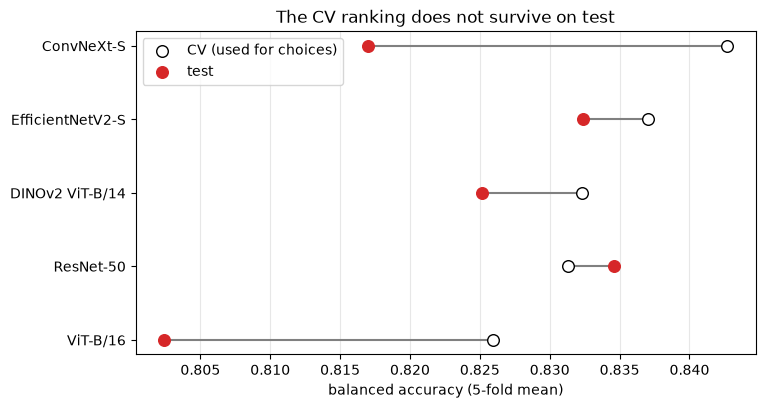

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(bb))[::-1]
ax.hlines(y, bb.cv_bal_acc, bb.test_bal_acc, color="grey")
ax.scatter(bb.cv_bal_acc, y, s=70, facecolors="white", edgecolors="k", zorder=3, label="CV (used for choices)")
ax.scatter(bb.test_bal_acc, y, s=70, color="C3", zorder=3, label="test")
ax.set_yticks(y, bb.index); ax.set_xlabel("balanced accuracy (5-fold mean)"); ax.grid(axis="x", alpha=.3); ax.legend()
ax.set_title("The CV ranking does not survive on test");

## 3. Averaging across backbones

In [6]:
members = list(runs.values())
if not (A.RESULTS / "ens4_no_vit_res448_tta20_la").exists():   # CPU, seconds
    run("python ensemble_runs.py --name ens4_no_vit_res448_tta20_la " + " ".join(m for m in members if "vit_b16" not in m))
if not (A.RESULTS / "ens5_res448_tta20_la").exists():
    run("python ensemble_runs.py --name ens5_res448_tta20_la " + " ".join(members))
cands = {"all 5 backbones": "ens5_res448_tta20_la", "4 without ViT": "ens4_no_vit_res448_tta20_la",
         "best single on CV (ConvNeXt-S)": runs["ConvNeXt-S"], "optimised ResNet-50": REF}
display(A.summary(list(cands.values()), "cv_val", names=list(cands), ensemble=False)[["bal_acc", "auc", "mel_sens"]])
A.summary(list(cands.values()), names=list(cands))

,bal_acc,auc,mel_sens
all 5 backbones,0.873 ± 0.014,0.986 ± 0.002,0.798 ± 0.024
4 without ViT,0.871 ± 0.014,0.986 ± 0.003,0.799 ± 0.026
best single on CV (ConvNeXt-S),0.843 ± 0.020,0.979 ± 0.003,0.750 ± 0.057
optimised ResNet-50,0.831 ± 0.016,0.972 ± 0.003,0.746 ± 0.025


,bal_acc,acc,f1,auc,mel_sens,mel_spec,ensemble_bal_acc,n_folds
all 5 backbones,0.877 ± 0.014,0.873 ± 0.013,0.818 ± 0.022,0.984 ± 0.001,0.811 ± 0.025,0.939 ± 0.002,0.892,5
4 without ViT,0.871 ± 0.004,0.868 ± 0.012,0.809 ± 0.021,0.983 ± 0.002,0.804 ± 0.023,0.939 ± 0.003,0.887,5
best single on CV (ConvNeXt-S),0.817 ± 0.017,0.843 ± 0.015,0.761 ± 0.029,0.977 ± 0.002,0.747 ± 0.052,0.934 ± 0.014,0.862,5
optimised ResNet-50,0.835 ± 0.013,0.803 ± 0.020,0.720 ± 0.029,0.973 ± 0.003,0.759 ± 0.032,0.925 ± 0.007,0.87,5


All 25 models averaged on the official test set: balanced acc 0.892, accuracy 0.882, AUC 0.987, melanoma sensitivity 0.825 at specificity 0.937
Reference: Gessert et al. 54-model ensemble 0.856; ISIC 2018 winner (external data) 0.885


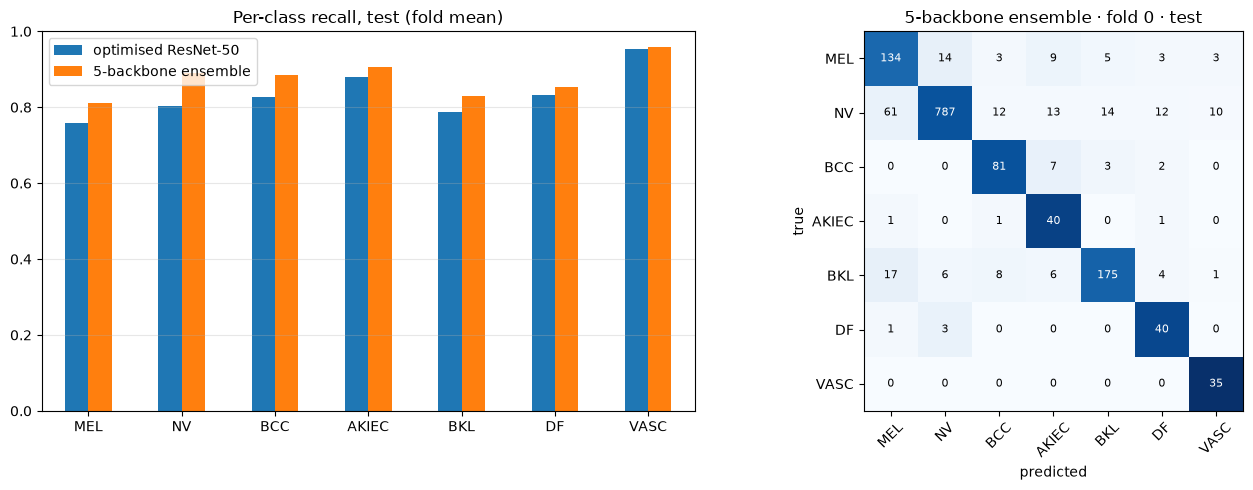

In [7]:
ENS = "ens5_res448_tta20_la"
e = A.fold_ensemble(ENS)
print(f"All 25 models averaged on the official test set: balanced acc {e['balanced_acc']:.3f}, accuracy {e['accuracy']:.3f}, "
      f"AUC {e['macro_auc']:.3f}, melanoma sensitivity {e['mel_sensitivity']:.3f} at specificity {e['mel_specificity']:.3f}")
print("Reference: Gessert et al. 54-model ensemble 0.856; ISIC 2018 winner (external data) 0.885")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.DataFrame({"optimised ResNet-50": A.per_class_recall(REF), "5-backbone ensemble": A.per_class_recall(ENS)}).plot.bar(ax=axes[0], rot=0)
axes[0].set_ylim(0, 1); axes[0].grid(axis="y", alpha=.3); axes[0].set_title("Per-class recall, test (fold mean)")
A.plot_confusion(axes[1], ENS, 0, "5-backbone ensemble · fold 0 · test")
plt.tight_layout()

## Takeaways
* **The learning rate matters more than the architecture:** transformers need 5e-5; at ResNet's 2e-4 DINOv2 falls to 0.718.
* **No single stronger backbone beats ResNet-50 on test** (−0.002 to −0.032), although all have slightly higher test AUC.
  ConvNeXt-S led on CV (0.843) but scored 0.817 on test: CV differences of this size are within fold noise, and the test set
  differs from HAM10000 in class mix and image sources.
* **Averaging the five backbones is the clear CV winner** (0.873 vs 0.843) and the gain holds on test: 0.877 per fold,
  **0.892 for all 25 models** with 0.825 melanoma sensitivity — above the paper's 54-model ensemble (0.856) and the
  ISIC 2018 winner (0.885). Different architectures make different mistakes.